# Transient heat conduction: a plate with a localized heater

A heater supplies heat near the right side of a thin metal plate. The left edge is held at coolant temperature $T_c=300\,\mathrm K$. The other edges and the broad faces are insulated. Temperature is assumed uniform through the thickness.

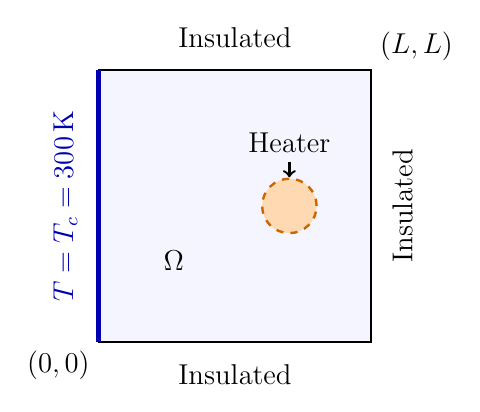

## Problem
Let $\Gamma_T$ be the left edge and $\Gamma_q$ the other three edges. With outward unit normal $\boldsymbol n$,
$$
\begin{cases}
\rho c\,\partial_tT-\nabla\cdot(k\nabla T)=r(x,y)&\text{in }\Omega=(0,L)^2,\quad 0<t\le60\,\mathrm s,\\
T=T_c&\text{on }\Gamma_T,\\
k\nabla T\cdot\boldsymbol n=0&\text{on }\Gamma_q,\\
T(x,y,0)=T_c&\text{in }\Omega.
\end{cases}
$$
Use $L=0.1\,\mathrm m$, $k=200\,\mathrm{W/(m\,K)}$, $\rho=2700\,\mathrm{kg/m^3}$, and $c=900\,\mathrm{J/(kg\,K)}$. The thermal diffusivity is
$$
\boxed{\alpha=\frac{k}{\rho c}=8.23\times10^{-5}\,\mathrm{m^2/s}.}
$$
The heater remains on and supplies
$$
r(x,y)=r_0\exp\left[-\frac{(x-x_H)^2+(y-y_H)^2}{2w^2}\right],
\quad r_0=2\times10^6\,\mathrm{W/m^3},
$$
where $(x_H,y_H)=(0.07,0.05)\,\mathrm m$ and $w=0.01\,\mathrm m$. For a $1\,\mathrm{mm}$ thick plate, this is approximately $1.3\,\mathrm W$ of heating.

Use **Python (Finite Elements)** and run the cells in order. Saved outputs show a completed run.

## Time-step equation
The trial temperature satisfies $T=T_c$ on the left edge; test functions vanish there. The insulated edges contribute zero to the boundary integral. Define
$$
m(S,v)=\int_\Omega\rho c\,Sv\,\mathrm dx,\quad
a_T(S,v)=\int_\Omega k\nabla S\cdot\nabla v\,\mathrm dx,\quad
\ell_T(v)=\int_\Omega rv\,\mathrm dx.
$$
Since the source is constant in time, the $\theta$-method gives
$$
\begin{aligned}
m(T_h^{n+1},v_h)+\theta\Delta t\,a_T(T_h^{n+1},v_h)
={}&m(T_h^n,v_h)\\
&-(1-\theta)\Delta t\,a_T(T_h^n,v_h)+\Delta t\,\ell_T(v_h).
\end{aligned}
$$
We begin with backward Euler, $\theta=1$: one linear solve per step.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import pandas as pd
import ufl
from mpi4py import MPI
from dolfinx import fem, mesh, plot
from dolfinx.fem.petsc import LinearProblem

plt.rcParams.update({"font.size": 12})

### Plotting routine
This routine draws the temperatures on the triangular FE mesh. The solve follows below.

In [2]:
def plot_temperatures(V, fields, times):
    topology, cell_types, coordinates = plot.vtk_mesh(V)
    triangles = topology.reshape(-1, 4)[:, 1:]
    triangulation = mtri.Triangulation(
        coordinates[:, 0], coordinates[:, 1], triangles)
    levels = np.linspace(T_c, max(values.max() for values in fields), 17)
    fig, axes = plt.subplots(1, len(fields), figsize=(12, 3.8),
                             constrained_layout=True)
    for ax, values, time in zip(axes, fields, times):
        contour = ax.tricontourf(triangulation, values, levels=levels)
        fig.colorbar(contour, ax=ax, label="T (K)")
        ax.set(xlabel="x (m)", ylabel="y (m)",
               title=f"t = {time:g} s", aspect="equal")
    return fig

## 1. Material, mesh, and boundary condition
Use linear triangular elements. Only the cooled left edge requires a prescribed-temperature condition. Zero flux on the other edges needs no added boundary integral.

In [3]:
L_plate = 0.1
rho = 2700.0
c = 900.0
k = 200.0
alpha = k / (rho*c)
T_c = 300.0

domain = mesh.create_rectangle(
    MPI.COMM_SELF, [np.array([0.0, 0.0]), np.array([L_plate, L_plate])],
    [24, 24], cell_type=mesh.CellType.triangle)
V = fem.functionspace(domain, ("Lagrange", 1))

def cooled_edge(x):
    return np.isclose(x[0], 0.0)

boundary_dofs = fem.locate_dofs_geometrical(V, cooled_edge)
T_D = fem.Function(V)
T_D.x.array[:] = T_c
bc = fem.dirichletbc(T_D, boundary_dofs)
T_n = fem.Function(V)
T_n.x.array[:] = T_c
print(f"Thermal diffusivity: {alpha:.4e} m^2/s")

Thermal diffusivity: 8.2305e-05 m^2/s


## 2. Source and forms
The code uses <code>rho*c*alpha</code>, which equals <code>k</code>. The source is the Gaussian heater defined above. The solver uses direct LU factorization; its options prefix names this solver's settings.

In [4]:
x = ufl.SpatialCoordinate(domain)
r0 = 2.0e6
x_H, y_H = 0.07, 0.05
w = 0.01
r = r0*ufl.exp(-((x[0]-x_H)**2 + (x[1]-y_H)**2)/(2*w**2))

final_time = 60.0
num_steps = 30
dt = fem.Constant(domain, final_time / num_steps)
theta = fem.Constant(domain, 1.0)
S = ufl.TrialFunction(V)
v = ufl.TestFunction(V)
dx = ufl.Measure("dx", domain=domain)

def m(S, v):
    return rho*c*S*v*dx

def a_T(S, v):
    return rho*c*alpha*ufl.inner(ufl.grad(S), ufl.grad(v))*dx

A = m(S, v) + theta*dt*a_T(S, v)
L = m(T_n, v) - (1-theta)*dt*a_T(T_n, v) + dt*r*v*dx
problem = LinearProblem(
    A, L, bcs=[bc], petsc_options_prefix="heat_step_",
    petsc_options={"ksp_type": "preonly", "pc_type": "lu"})

## 3. Time loop
At each step, solve for the new field and copy its coefficients into the old field <code>T_n</code>. Source and boundary values remain fixed. Save the fields at 10, 30, and 60 seconds for plotting.

In [5]:
theta.value = 1.0
dt.value = final_time / num_steps
T_n.x.array[:] = T_c
saved_fields = []
saved_times = []

for n in range(num_steps):
    T_new = problem.solve()
    T_n.x.array[:] = T_new.x.array
    time = (n+1)*float(dt.value)

    if n+1 in [5, 15, 30]:
        saved_fields.append(T_n.x.array.copy())
        saved_times.append(time)

print(f"Maximum temperature at 60 s: {T_n.x.array.max():.3f} K")

Maximum temperature at 60 s: 303.668 K


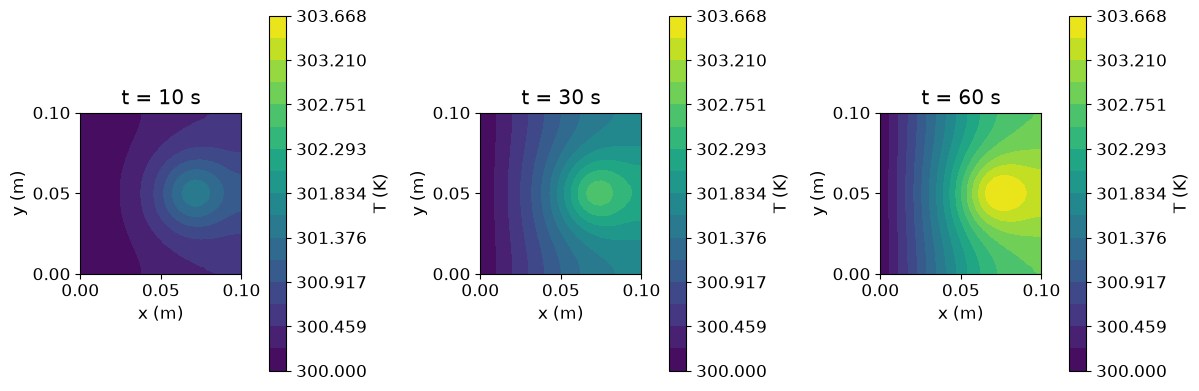

In [6]:
fig_solution = plot_temperatures(V, saved_fields, saved_times)
plt.show()

## 4. Time-step comparison
Keep the mesh fixed. Repeat with $\Delta t=4,\ 2,\ 1\,\mathrm s$, resetting the initial temperature each time. For linear triangular elements, the maximum FE temperature is the largest nodal value.

The last column compares successive computed final fields:
$$
D=\left(\int_\Omega[T_{h,\Delta t}(\cdot,60)-T_{h,2\Delta t}(\cdot,60)]^2\,\mathrm dx\right)^{1/2}.
$$
It measures the change when the time step is halved, not the error against an exact solution.

In [7]:
step_counts = [15, 30, 60]
maximum_temperatures = []
differences = []
T_previous = fem.Function(V)

for i, steps in enumerate(step_counts):
    dt.value = final_time / steps
    T_n.x.array[:] = T_c

    for n in range(steps):
        T_new = problem.solve()
        T_n.x.array[:] = T_new.x.array

    maximum_temperatures.append(T_n.x.array.max())
    if i == 0:
        differences.append(np.nan)
    else:
        difference = fem.form((T_n-T_previous)**2*dx)
        differences.append(np.sqrt(fem.assemble_scalar(difference)))
    T_previous.x.array[:] = T_n.x.array

pd.DataFrame({
    "Time step (s)": final_time / np.array(step_counts),
    "Maximum T at 60 s (K)": maximum_temperatures,
    "L2 difference from coarser step (K m)": differences,
})

,Time step (s),Maximum T at 60 s (K),L2 difference from coarser step (K m)
0,4.0,303.639290,NaN
1,2.0,303.668273,0.002217
2,1.0,303.683077,0.001133


To compare materials, change <code>k</code>, <code>rho</code>, or <code>c</code>, recompute <code>alpha</code>, and rerun from Section 2. Spatial error requires a separate mesh-refinement check.

### References
Larson and Bengzon, *The Finite Element Method: Theory, Implementation, and Practice* (2010 notes), Chapter 5, §§5.1.4–5.1.5, pp. 99–101. Arnold, *Lecture Notes on Numerical Analysis of Partial Differential Equations*, Chapter 5, §3, pp. 93–94. [FEniCSx heat-equation tutorial](https://jsdokken.com/dolfinx-tutorial/stable/chapter2/heat_code.html).